In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('../Files/titanic_data_updated.csv')
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,no,third,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,yes,first,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,yes,third,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,yes,first,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,no,third,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [8]:
df.shape

print(f"Total Potential Features    : {df.shape[1]}")
print(f"Total Potential Sample Data : {df.shape[0]}")

Total Potential Features    : 12
Total Potential Sample Data : 891


In [10]:
df.head(10)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,no,third,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,yes,first,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,yes,third,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,yes,first,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,no,third,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
5,6,no,third,"Moran, Mr. James",male,NaN,0,0,330877,8.4583,NaN,Q
6,7,no,first,"McCarthy, Mr. Timothy J",male,54.0,0,0,17463,51.8625,E46,S
7,8,no,third,"Palsson, Master. Gosta Leonard",male,2.0,3,1,349909,21.0750,NaN,S
8,9,yes,third,"Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)",female,27.0,0,2,347742,11.1333,NaN,S
9,10,yes,second,"Nasser, Mrs. Nicholas (Adele Achem)",female,14.0,1,0,237736,30.0708,NaN,C


In [12]:
df.sample(10)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
273,274,no,first,"Natsch, Mr. Charles H",male,37.0,0,1,PC 17596,29.7000,C118,C
199,200,no,second,"Yrois, Miss. Henriette (""Mrs Harbeck"")",female,24.0,0,0,248747,13.0000,NaN,S
667,668,no,third,"Rommetvedt, Mr. Knud Paust",male,NaN,0,0,312993,7.7750,NaN,S
529,530,no,second,"Hocking, Mr. Richard George",male,23.0,2,1,29104,11.5000,NaN,S
504,505,yes,first,"Maioni, Miss. Roberta",female,16.0,0,0,110152,86.5000,B79,S
410,411,no,third,"Sdycoff, Mr. Todor",male,NaN,0,0,349222,7.8958,NaN,S
681,682,yes,first,"Hassab, Mr. Hammad",male,27.0,0,0,PC 17572,76.7292,D49,C
434,435,no,first,"Silvey, Mr. William Baird",male,50.0,1,0,13507,55.9000,E44,S
89,90,no,third,"Celotti, Mr. Francesco",male,24.0,0,0,343275,8.0500,NaN,S
765,766,yes,first,"Hogeboom, Mrs. John C (Anna Andrews)",female,51.0,1,0,13502,77.9583,D11,S


In [13]:
df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [15]:
df.duplicated().sum()
df.drop_duplicates(inplace=True)

C:\Users\00971554820138\AppData\Local\Temp\ipykernel_10196\906160537.py:2: Pandas4Warning: The inplace keyword in DataFrame.drop_duplicates is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop_duplicates(inplace=True)


In [17]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    str    
 2   Pclass       891 non-null    str    
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(3), str(7)
memory usage: 125.5 KB


In [18]:
df.describe()

,PassengerId,Age,SibSp,Parch,Fare
count,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,29.699118,0.523008,0.381594,32.204208
std,257.353842,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,38.000000,1.000000,0.000000,31.000000
max,891.000000,80.000000,8.000000,6.000000,512.329200


# Univariate analysis (Chategorical)

<Axes: xlabel='Survived', ylabel='count'>

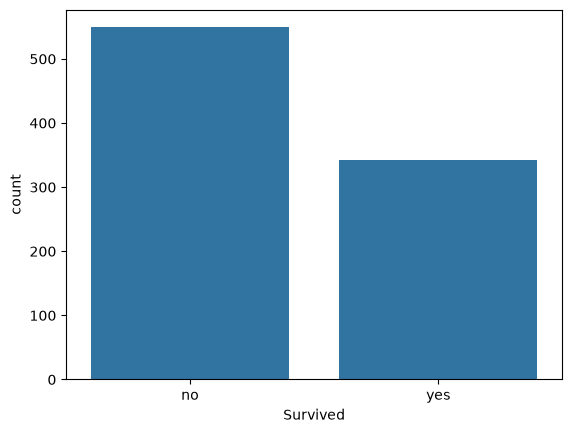

In [19]:
sns.countplot(data=df, x=df['Survived'])

In [22]:
df['Survived'].value_counts()

Survived
no     549
yes    342
Name: count, dtype: int64

In [23]:
( df['Survived'].value_counts() / len(df) ) * 100

Survived
no     61.616162
yes    38.383838
Name: count, dtype: float64

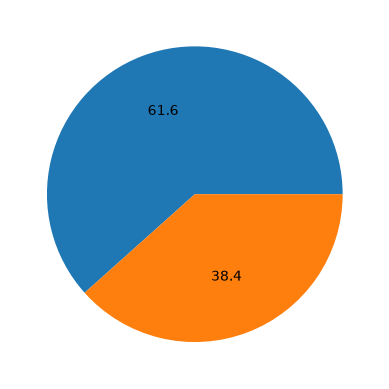

In [25]:
survived_count = df['Survived'].value_counts()

plt.pie(survived_count, autopct='%1.1f')

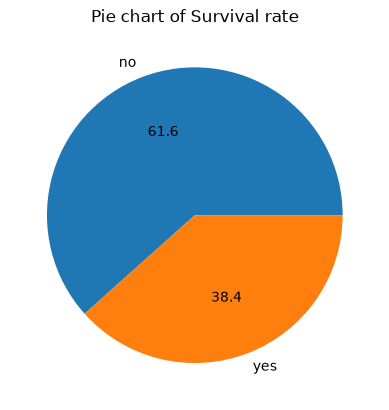

In [28]:
survived_count = df['Survived'].value_counts()

survived_label = df['Survived'].unique()

plt.pie(survived_count, autopct='%1.1f', labels=survived_label)
plt.title('Pie chart of Survival rate')
plt.show()

<Axes: xlabel='Pclass', ylabel='count'>

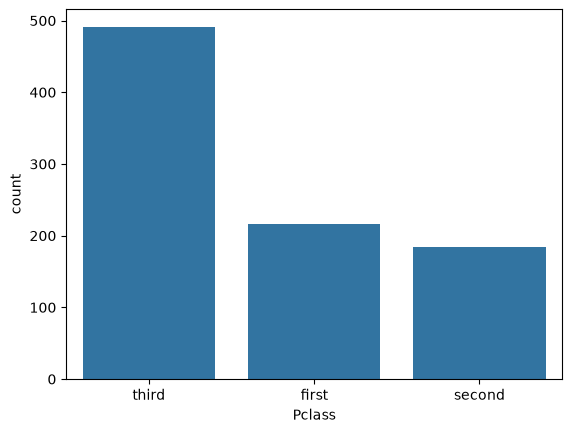

In [29]:
sns.countplot(data=df, x=df['Pclass'])

In [30]:
(df['Pclass'].value_counts() / len(df)) * 100

Pclass
third     55.106622
first     24.242424
second    20.650954
Name: count, dtype: float64

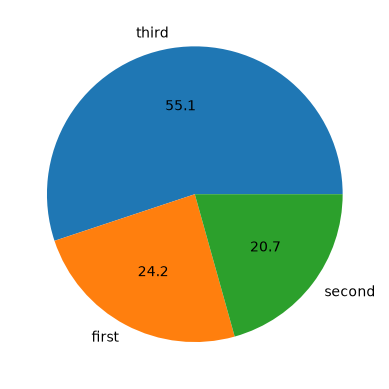

In [33]:
pclass = df['Pclass'].value_counts()

pclass_label = df['Pclass'].unique()


plt.pie(pclass, labels=pclass_label, autopct='%1.1f')

<Axes: xlabel='Sex', ylabel='count'>

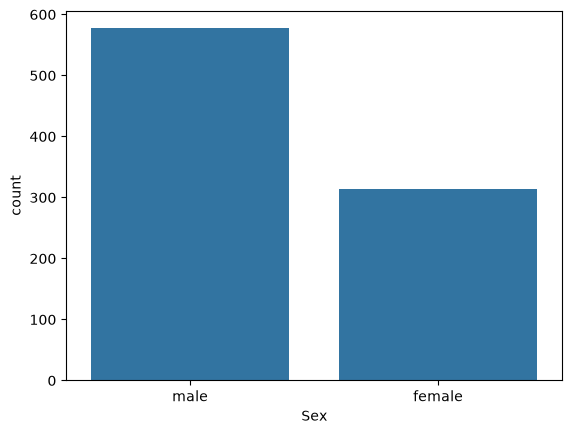

In [35]:
sns.countplot(data=df, x=df['Sex'])

In [36]:
(df['Sex'].value_counts() / len(df)) * 100

Sex
male      64.758698
female    35.241302
Name: count, dtype: float64

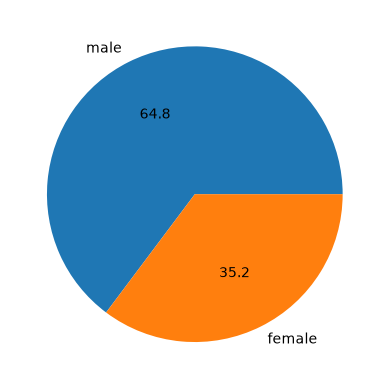

In [37]:
Gender = df['Sex'].value_counts()
Gender_label = df['Sex'].unique()
plt.pie(Gender, autopct='%1.1f', labels=Gender_label)

<Axes: xlabel='Embarked', ylabel='count'>

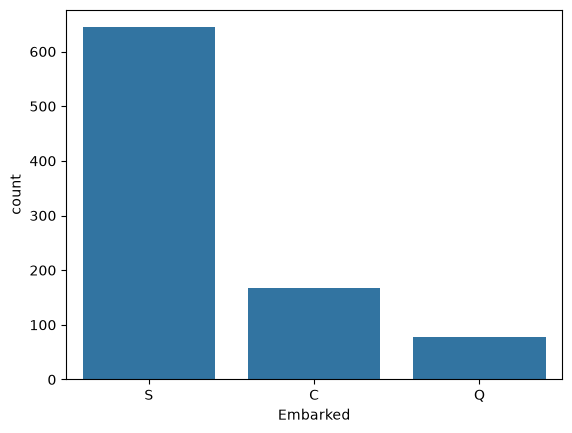

In [38]:
sns.countplot(data=df, x=df['Embarked'])

In [39]:
(df['Embarked'].value_counts() / len(df)) * 100


Embarked
S    72.278339
C    18.855219
Q     8.641975
Name: count, dtype: float64

<ArrowStringArray>
['S', 'C', 'Q']
Length: 3, dtype: str


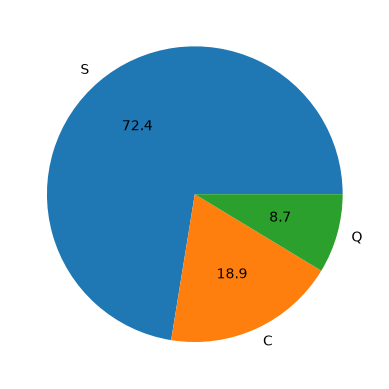

In [ ]:
port = df['Embarked'].value_counts()
port_label = df['Embarked'].dropna().unique()
plt.pie(port, labels=port_label, autopct='%1.1f')

Text(0.5, 1.0, 'Histogram of Age')

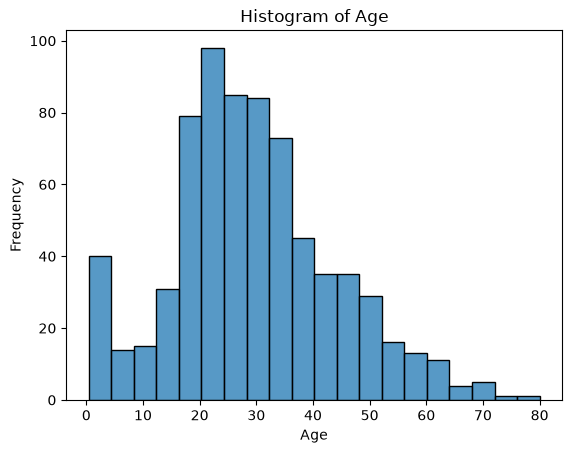

In [48]:
sns.histplot(data=df['Age'])

plt.ylabel('Frequency')
plt.title('Histogram of Age')

Text(0.5, 1.0, 'Histogram of Age')

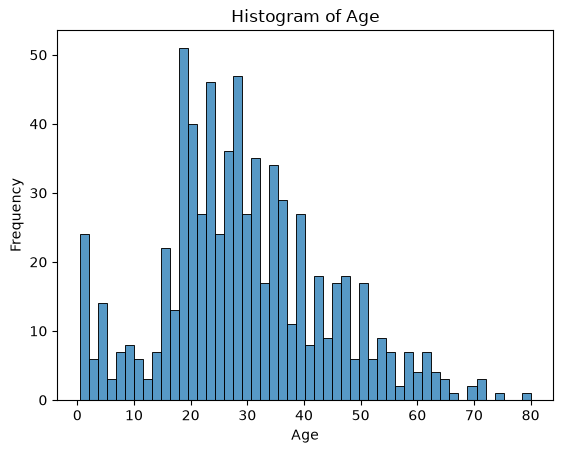

In [49]:
sns.histplot(data=df['Age'], bins=50)

plt.ylabel('Frequency')
plt.title('Histogram of Age')

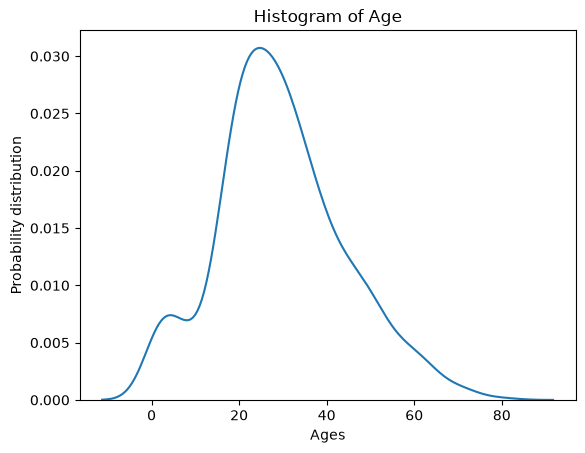

In [51]:
sns.kdeplot(data=df['Age'])
plt.xlabel('Ages')
plt.ylabel('Probability distribution')
plt.title('Histogram of Age')
plt.show()

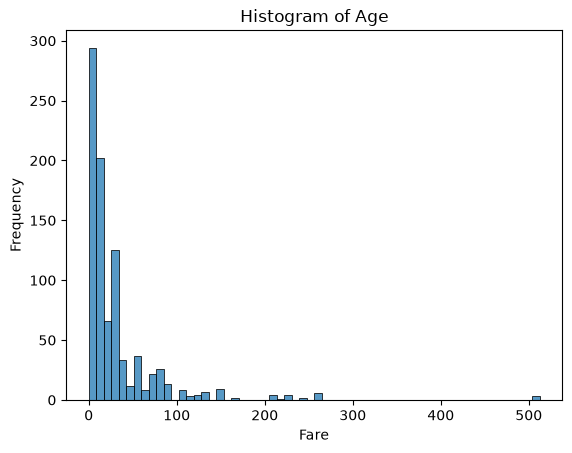

In [55]:
sns.histplot(data=df['Fare'])

plt.ylabel('Frequency')
plt.title('Histogram of Age')
plt.show()

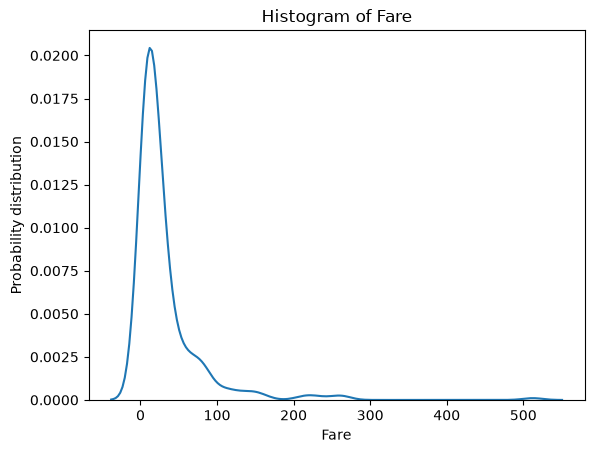

In [56]:
sns.kdeplot(data=df['Fare'])
plt.xlabel('Fare')
plt.ylabel('Probability distribution')
plt.title('Histogram of Fare')
plt.show()

<Axes: ylabel='Fare'>

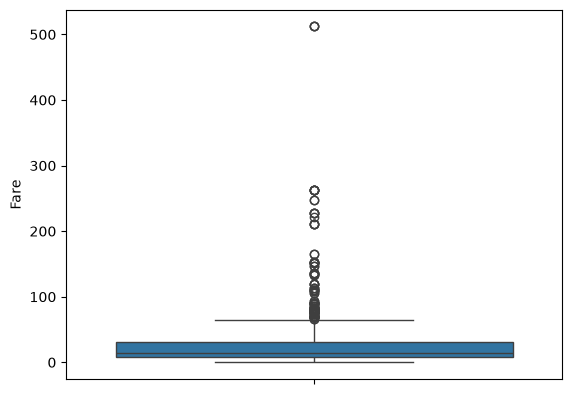

In [57]:
sns.boxplot(data=df['Fare'])
